# 01 — Datasets

Loading of **MNIST** and **CIFAR-10** for the plasticity benchmarks of *Non-Stationary Learning of Neural Networks with Automatic Soft Parameter Reset* (Galashov et al., NeurIPS 2024, [arXiv:2411.04034](https://arxiv.org/abs/2411.04034)).

Every task of the stream reuses the same fixed set of 10,000 images. We use the official **test split** of each dataset (10k images).

## 0. Setup (Google Colab only)

On Colab, the notebook runs alone in `/content`, without the rest of the repository. This cell clones the repository and moves into it, so that the project files (`src/`, `scripts/`, `data/`) are available. Locally, it does nothing.

On Colab, select a GPU first: *Runtime → Change runtime type → GPU*.

In [2]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    REPO_ROOT = Path("/content/nonstationary-nn-streams")
    if not REPO_ROOT.exists():
        !git clone -q https://github.com/younes-oudina/nonstationary-nn-streams.git {REPO_ROOT}
    %cd {REPO_ROOT}
    !git pull -q

## 1. Imports, device and paths

- `device`: GPU (`cuda`) if available, otherwise CPU.
- Raw files are stored in `data/` at the root of the repository (ignored by git).

In [3]:
from pathlib import Path

import torch
from torchvision import datasets

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"device: {device}")

DATA_DIR = Path("../data") if Path.cwd().name == "notebooks" else Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.resolve()

device: cpu


PosixPath('/home/youns_speed/ip_paris/nonstationary-nn-streams/data')

## 2. Download

`download=True` only downloads the files if they are not already in `DATA_DIR`.

In [4]:
mnist = datasets.MNIST(root=DATA_DIR, train=False, download=True)
cifar10 = datasets.CIFAR10(root=DATA_DIR, train=False, download=True)

## 3. Conversion to tensors

Images are converted to float tensors of shape $(N, C, H, W)$ and normalised as in App. D.1 of the paper:
$$x \in \{0, \dots, 255\} \;\longmapsto\; \frac{x}{255} \in [0, 1]$$

The whole set (10k images) is moved to `device` once: it fits in GPU memory, so no `DataLoader` is needed.

In [5]:
X_mnist = mnist.data.float().div(255).unsqueeze(1).to(device)                       # (10000, 1, 28, 28)
y_mnist = mnist.targets.to(device)                                                  # (10000,)

X_cifar = torch.from_numpy(cifar10.data).permute(0, 3, 1, 2).float().div(255).to(device)  # (10000, 3, 32, 32)
y_cifar = torch.tensor(cifar10.targets, device=device)                              # (10000,)

print(f"MNIST    X {tuple(X_mnist.shape)}  y {tuple(y_mnist.shape)}  range [{X_mnist.min():.1f}, {X_mnist.max():.1f}]  on {X_mnist.device}")
print(f"CIFAR-10 X {tuple(X_cifar.shape)}  y {tuple(y_cifar.shape)}  range [{X_cifar.min():.1f}, {X_cifar.max():.1f}]  on {X_cifar.device}")

MNIST    X (10000, 1, 28, 28)  y (10000,)  range [0.0, 1.0]  on cpu
CIFAR-10 X (10000, 3, 32, 32)  y (10000,)  range [0.0, 1.0]  on cpu


## 4. Permuted MNIST stream

Each task applies a **fixed random permutation** $\pi_k$ to the 784 pixels of all images; labels are unchanged. Only the input distribution shifts from one task to the next.

The parameters are read from [`configs/permuted_mnist.yaml`](../configs/permuted_mnist.yaml). The paper (App. D.1) says it follows the regime of Kumar et al. 2023 (its ref. [34]); values it does not state are taken from Kumar et al.:

| Parameter | Value | Source |
|---|---|---|
| Images per task | 10,000 (fixed for all tasks) | Soft Resets D.1, Kumar Table 1 |
| Normalisation | $x/255 \in [0,1]$, flattened to 784 | Soft Resets D.1 |
| Batch size | 16 | Soft Resets D.1, Kumar Table 1 |
| Epochs per task | 1, so 625 steps per task | Soft Resets D.1, Kumar Table 1 |
| Number of tasks | 500 | Kumar Table 1 (not given in Soft Resets) |
| Model | MLP 4 × 256, ReLU, PyTorch default init | Soft Resets D.1, Kumar Sec. 5 |
| Optimiser | online SGD, lr = 0.1 | Soft Resets D.1 |
| Seeds | 3 | Soft Resets Sec. 5 |

The permutation of task $k$ and the order of its batches only depend on `(seed, k)`, so every task can be rebuilt on its own.

In [6]:
import sys

REPO = DATA_DIR.resolve().parent
sys.path.insert(0, str(REPO / "src"))  # not needed if the package is installed (uv sync)

from softresets.config import load_config
from softresets.data import PermutedMNISTStream, load_image_dataset

cfg = load_config(REPO / "configs" / "permuted_mnist.yaml")
cfg

{'name': 'permuted_mnist',
 'data': {'dataset': 'mnist',
  'root': 'data',
  'split': 'test',
  'num_images': 10000,
  'subset_seed': 0,
  'normalize': True,
  'flatten': True},
 'stream': {'num_tasks': 500,
  'batch_size': 16,
  'epochs_per_task': 1,
  'permute_first_task': True},
 'model': {'type': 'mlp',
  'hidden_sizes': [256, 256, 256, 256],
  'activation': 'relu',
  'init': 'pytorch_default'},
 'optim': {'name': 'sgd', 'lr': 0.1},
 'eval': {'metric': 'online_accuracy'},
 'seeds': [0, 1, 2]}

In [7]:
data_cfg = cfg["data"]
X, y = load_image_dataset(
    data_cfg["dataset"],
    root=DATA_DIR,
    split=data_cfg["split"],
    num_images=data_cfg["num_images"],
    subset_seed=data_cfg["subset_seed"],
    normalize=data_cfg["normalize"],
    flatten=data_cfg["flatten"],
    device=device,
)

stream = PermutedMNISTStream.from_config(X, y, cfg["stream"], seed=cfg["seeds"][0])

print(f"X {tuple(X.shape)} on {X.device}, y {tuple(y.shape)}")
print(f"{len(stream)} tasks x {stream.steps_per_task} steps = {len(stream) * stream.steps_per_task:,} online steps")

X (10000, 784) on cpu, y (10000,)
500 tasks x 625 steps = 312,500 online steps


### 4.1 Visualisation

Row 0 shows the original images; rows 1 to 4 show the same images as seen in tasks 0 to 3. The permuted images look like noise to a human, but each task is just as learnable as the original.

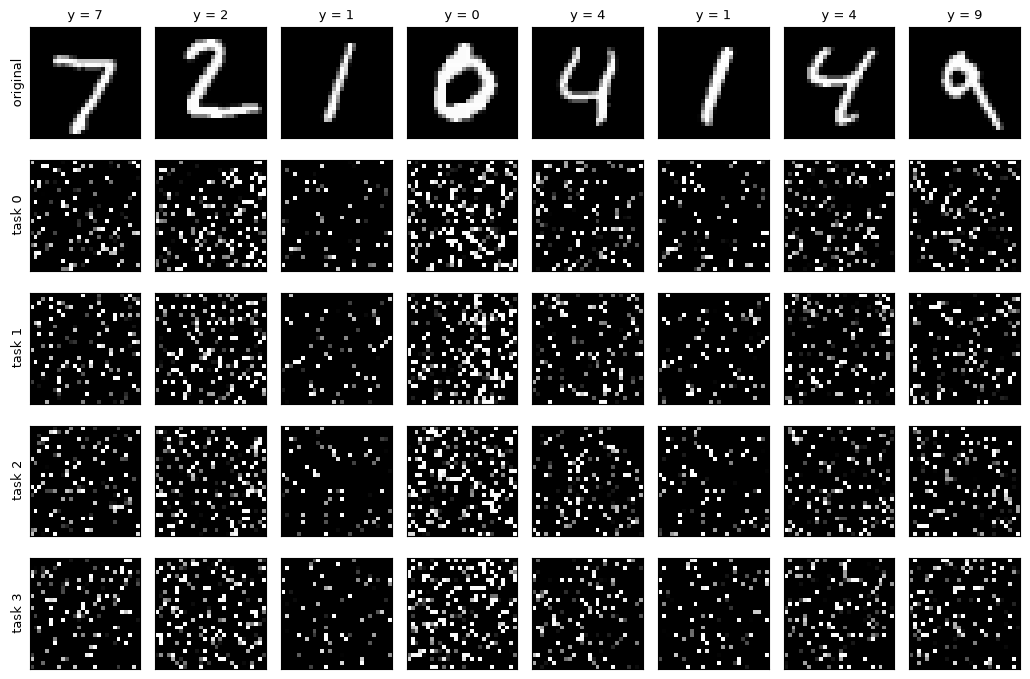

In [8]:
import matplotlib.pyplot as plt

n_img, n_tasks = 8, 4
fig, axes = plt.subplots(n_tasks + 1, n_img, figsize=(1.3 * n_img, 1.4 * (n_tasks + 1)))
rows = [("original", X)] + [(f"task {k}", stream.task(k).x) for k in range(n_tasks)]
for r, (name, imgs) in enumerate(rows):
    for c in range(n_img):
        ax = axes[r, c]
        ax.imshow(imgs[c].view(28, 28).cpu(), cmap="gray")
        ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(name, fontsize=9)
        if r == 0:
            ax.set_title(f"y = {y[c].item()}", fontsize=9)
plt.tight_layout()
plt.show()